<a href="https://colab.research.google.com/github/minhphu12-oc/gg-colab/blob/sklearn-project-for-machine-learning/project_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import torchvision
import torchvision.transforms as transforms
train_set = torchvision.datasets.CIFAR10(root="./data", train=True, download=True, transform=transforms.ToTensor())
test_set = torchvision.datasets.CIFAR10(root="./data", train=False, download=True, transform=transforms.ToTensor())

100%|██████████| 170M/170M [34:04<00:00, 83.4kB/s]


In [7]:
# chia thành các batch
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

x_train_tensor = torch.tensor(train_set.data, dtype=torch.float32).permute(0, 3, 1, 2) / 255.0
y_train_tensor = torch.tensor(train_set.targets, dtype=torch.long)

x_test_tensor = torch.tensor(test_set.data, dtype=torch.float32).permute(0, 3, 1, 2) / 255.0
y_test_tensor = torch.tensor(test_set.targets, dtype=torch.long)

tensor_train = TensorDataset(x_train_tensor, y_train_tensor)
train_loader = DataLoader(tensor_train, batch_size=100, shuffle=True)

tensor_test = TensorDataset(x_test_tensor, y_test_tensor)
test_loader = DataLoader(tensor_test, batch_size=100, shuffle=True)

x_train, y_train = next(iter(train_loader))
x_test, y_test = next(iter(test_loader))

In [14]:
# xem thông tin dữ liệu
print(f"x_train: {x_train_tensor.shape}")
print(f"y_train: {len(y_train_tensor)}")
print(f"x_test: {x_test_tensor.shape}")
print(f"y_test: {len(y_test_tensor)}")

x_train: torch.Size([50000, 3, 32, 32])
y_train: 50000
x_test: torch.Size([10000, 3, 32, 32])
y_test: 10000


dữ liệu có 50000 dữ liệu , 3 tầng màu , chiều cao 32, chiều dài 32, chia thành các batch 100 để model chạy nhanh hơn

In [88]:
# xây dựng model
class CNN(nn.Module):
  def __init__(self, input, hid1, hid2, hid3, hid4, out, drop):
    super().__init__()
    self.conv1 = nn.Conv2d(input, hid1, kernel_size=3, stride = 1 ,padding=1)
    self.bn1 = nn.BatchNorm2d(hid1)
    self.relu1 = nn.ReLU()
    self.mp1 = nn.MaxPool2d(kernel_size=2, stride=2)

    self.conv2 = nn.Conv2d(hid1, hid2, kernel_size=3, stride = 1 ,padding=1)
    self.bn2 = nn.BatchNorm2d(hid2)
    self.relu2 = nn.ReLU()
    self.mp2 = nn.MaxPool2d(kernel_size=2, stride=2)

    self.conv3 = nn.Conv2d(hid2, hid3, kernel_size=3, stride = 1 ,padding=1)
    self.bn3 = nn.BatchNorm2d(hid3)
    self.relu3 = nn.ReLU()
    self.mp3 = nn.MaxPool2d(kernel_size=2, stride=2)

    self.conv4 = nn.Conv2d(hid3, hid4, kernel_size=3, stride = 1 ,padding=1)
    self.bn4 = nn.BatchNorm2d(hid4)
    self.relu4 = nn.ReLU()
    self.mp4 = nn.MaxPool2d(kernel_size=2, stride=2)

    self.conv5 = nn.Conv2d(hid4, out, kernel_size=3, stride = 1 ,padding=1)
    self.bn5 = nn.BatchNorm2d(out)
    self.relu5 = nn.ReLU()
    self.mp5 = nn.MaxPool2d(kernel_size=2, stride=2)

    self.drop = nn.Dropout(drop)
    self.flatten = nn.Flatten()
    self.fc1 = nn.Linear(10, 10)

  def forward(self, x):
    x = self.conv1(x)
    x = self.bn1(x)
    x = self.relu1(x)
    x = self.mp1(x)

    x = self.conv2(x)
    x = self.bn2(x)
    x = self.relu2(x)
    x = self.mp2(x)

    x = self.conv3(x)
    x = self.bn3(x)
    x = self.relu3(x)
    x = self.mp3(x)

    x = self.conv4(x)
    x = self.bn4(x)
    x = self.relu4(x)
    x = self.mp4(x)

    x = self.conv5(x)
    x = self.bn5(x)
    x = self.relu5(x)
    x = self.mp5(x)

    x = self.drop(x)
    x = self.flatten(x)
    x = self.fc1(x)
    return x

# chia val để dùng early stopping từ các tensor đã định dạng đúng
x_val = x_train_tensor[:5000]
y_val = y_train_tensor[:5000]

x_train_split = x_train_tensor[5000:]
y_train_split = y_train_tensor[5000:]

val_loader = DataLoader(TensorDataset(x_val, y_val), batch_size=100, shuffle=True)
train_loader = DataLoader(TensorDataset(x_train_split, y_train_split), batch_size=100, shuffle=True)

In [89]:
# train model
model = CNN(3, 64, 128, 256, 512, 10, 0.2)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=0.001)
patience = 15
best_loss = float('inf')
patience_counter = 0
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)
import copy
best_model_wts = copy.deepcopy(model.state_dict())

for epoch in range(1000):
  model.train()
  epoch_loss = 0.0
  for x_batch, y_batch in train_loader:
    optimizer.zero_grad()
    x_batch = x_batch.to(device)
    y_batch = y_batch.to(device)
    y_pred = model(x_batch)
    loss = loss_fn(y_pred, y_batch)
    loss.backward()
    optimizer.step()
    epoch_loss += loss.item()
  epoch_loss /= len(train_loader)

  # dùng x_val, y_val để thử xem ở bước bao nhiêu là tốt nhất
  model.eval()
  val_loss = 0.0
  with torch.no_grad():
    for x_batch, y_batch in val_loader:
      x_batch = x_batch.to(device)
      y_batch = y_batch.to(device)
      y_pred = model(x_batch)
      val_loss += loss_fn(y_pred, y_batch).item()
    val_loss /= len(val_loader)
    print(f"Epoch {epoch}, Loss: {epoch_loss:.4f}, Val Loss: {val_loss:.4f}")

  if val_loss < best_loss:
    best_loss = val_loss
    patience_counter = 0
    # lưu trọng số tốt nhất
    best_model_wts = copy.deepcopy(model.state_dict())
  else:
    patience_counter += 1
    if patience_counter >= patience:
      print(f"Early stopping at epoch {epoch}. Best Val Loss: {best_loss:.4f}. Train loss : {loss}")
      print(f"val loss : {val_loss}")
      break

Epoch 0, Loss: 1.6168, Val Loss: 1.1828
Epoch 1, Loss: 1.1337, Val Loss: 0.9382
Epoch 2, Loss: 0.9411, Val Loss: 0.9671
Epoch 3, Loss: 0.8048, Val Loss: 0.8184
Epoch 4, Loss: 0.6974, Val Loss: 0.8533
Epoch 5, Loss: 0.5967, Val Loss: 0.6551
Epoch 6, Loss: 0.5221, Val Loss: 0.9963
Epoch 7, Loss: 0.4411, Val Loss: 0.8638
Epoch 8, Loss: 0.3759, Val Loss: 0.6969
Epoch 9, Loss: 0.3265, Val Loss: 0.6121
Epoch 10, Loss: 0.2806, Val Loss: 0.7023
Epoch 11, Loss: 0.2624, Val Loss: 0.8573
Epoch 12, Loss: 0.2259, Val Loss: 0.8599
Epoch 13, Loss: 0.2195, Val Loss: 0.7188
Epoch 14, Loss: 0.1976, Val Loss: 0.9594
Epoch 15, Loss: 0.1819, Val Loss: 0.7419
Epoch 16, Loss: 0.1645, Val Loss: 0.7508
Epoch 17, Loss: 0.1598, Val Loss: 0.7792
Epoch 18, Loss: 0.1578, Val Loss: 1.0614
Epoch 19, Loss: 0.1517, Val Loss: 0.8818
Epoch 20, Loss: 0.1523, Val Loss: 0.9090
Epoch 21, Loss: 0.1401, Val Loss: 0.7787
Epoch 22, Loss: 0.1364, Val Loss: 0.8513
Epoch 23, Loss: 0.1237, Val Loss: 0.8382
Epoch 24, Loss: 0.1343, Va

em thử rất nhiều cách rồi mà sao nó cứ bị underfitting hoặc là loss rất cao.

đổi neural (3, 16, 32, 64) và (3, 32, 64, 128)

thử cả đổi dropout từ 0.2 đến 0.8

thêm chỉ số weight_decay

nhưng vẫn bị loss rất cao

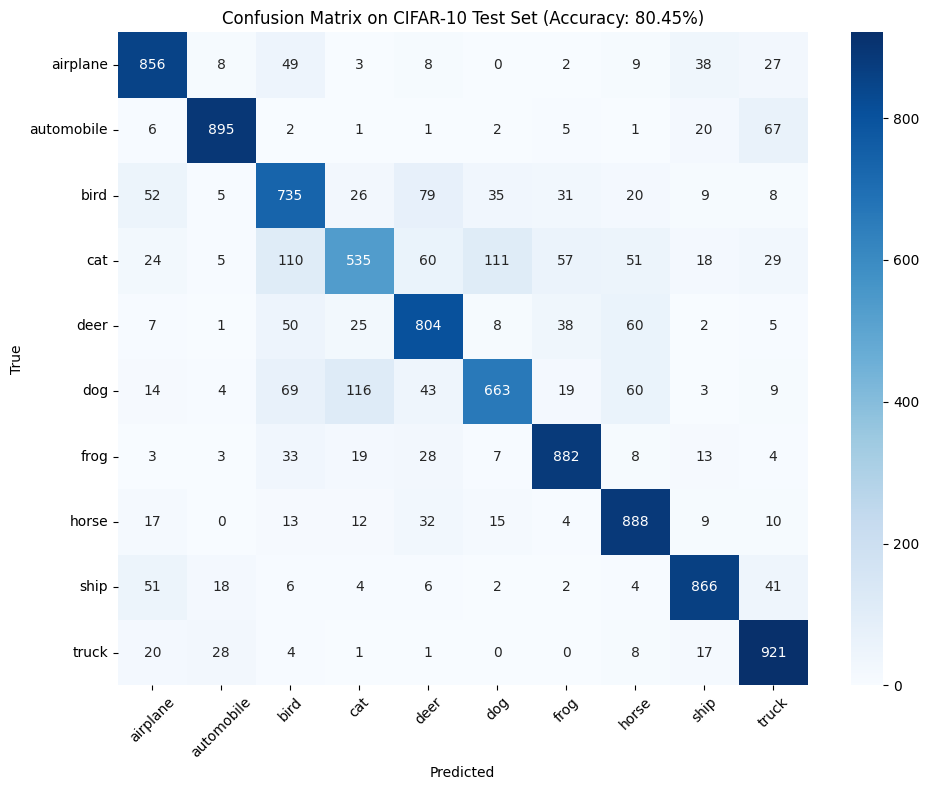

In [90]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import numpy as np

# Định nghĩa tên 10 lớp của CIFAR-10
classes = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

all_preds = []
all_targets = []

model.load_state_dict(best_model_wts)
model.eval()

with torch.no_grad():
    for x_batch, y_batch in test_loader:
        x_batch = x_batch.to(device)
        y_batch = y_batch.to(device)

        outputs = model(x_batch)
        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(y_batch.cpu().numpy())

cm = confusion_matrix(all_targets, all_preds)
accuracy = np.mean(np.array(all_preds) == np.array(all_targets)) * 100

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
plt.title(f'Confusion Matrix on CIFAR-10 Test Set (Accuracy: {accuracy:.2f}%)')
plt.ylabel('True')
plt.xlabel('Predicted')
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

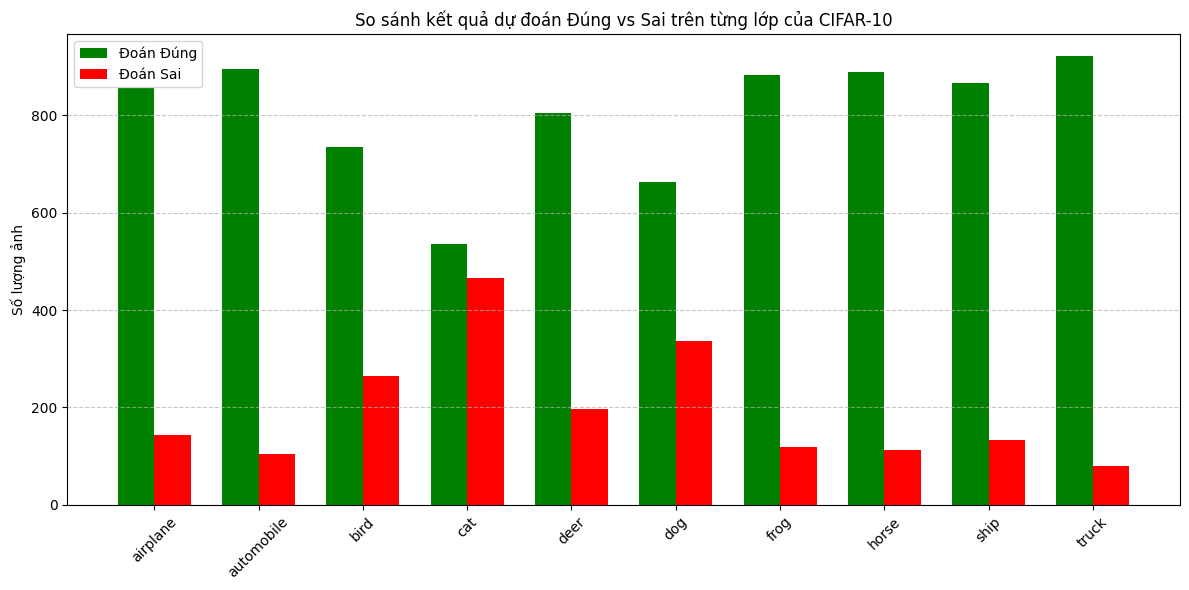

In [91]:
# Biểu đồ cột so sánh số lượng dự đoán đúng và sai cho từng lớp
correct_per_class = np.diag(cm)
total_per_class = np.sum(cm, axis=1)
incorrect_per_class = total_per_class - correct_per_class

x = np.arange(len(classes))
width = 0.35

fig, ax = plt.subplots(figsize=(12, 6))
rects1 = ax.bar(x - width/2, correct_per_class, width, label='Đoán Đúng', color='green')
rects2 = ax.bar(x + width/2, incorrect_per_class, width, label='Đoán Sai', color='red')

ax.set_ylabel('Số lượng ảnh')
ax.set_title('So sánh kết quả dự đoán Đúng vs Sai trên từng lớp của CIFAR-10')
ax.set_xticks(x)
ax.set_xticklabels(classes, rotation=45)
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.7)

fig.tight_layout()
plt.show()

ảnh mèo và chó đang bị đoán sai nhiều nhất nên ta sẽ thử lấy ảnh chó trên mạng để dự đoán xem có máy có thể nhận diện đúng không ?


In [98]:
from google.colab import files
fil_dog = files.upload()
fil_cat = files.upload()

Saving anh-cho-thumbnail.jpg to anh-cho-thumbnail (2).jpg


Saving images.jpg to images.jpg


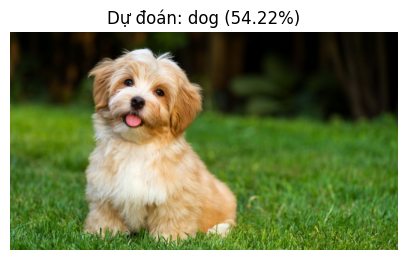

In [120]:
from PIL import Image
import torchvision.transforms as transforms


classes = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

image_path1 = 'anh-cho-thumbnail.jpg'
img1 = Image.open(image_path1).convert('RGB')

transform1 = transforms.Compose([transforms.Resize((32, 32)), transforms.ToTensor()])

img_tensor1 = transform1(img1).unsqueeze(0)

model.load_state_dict(best_model_wts)
model.eval()
with torch.no_grad():
    img_tensor = img_tensor1.to(device)
    output = model(img_tensor)
    probabilities = torch.nn.functional.softmax(output, dim=1)[0]
    _, pred = torch.max(output, 1)
    predicted_class = classes[pred.item()]
    confidence = probabilities[pred.item()].item() * 100

plt.figure(figsize=(5, 5))
plt.imshow(img1)
plt.title(f'Dự đoán: {predicted_class} ({confidence:.2f}%)')
plt.axis('off')
plt.show()

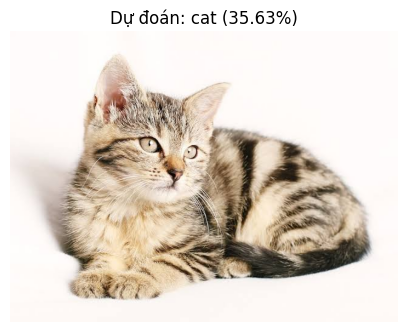

In [121]:
image_path2 = 'images.jpg'
img2 = Image.open(image_path2).convert('RGB')

transform2 = transforms.Compose([transforms.Resize((32, 32)), transforms.ToTensor()])

img_tensor2 = transform2(img2).unsqueeze(0)

model.load_state_dict(best_model_wts)
model.eval()
with torch.no_grad():
    img_tensor2 = img_tensor2.to(device)
    output = model(img_tensor2)
    probabilities = torch.nn.functional.softmax(output, dim=1)[0]
    _, pred = torch.max(output, 1)
    predicted_class = classes[pred.item()]
    confidence = probabilities[pred.item()].item() * 100

plt.figure(figsize=(5, 5))
plt.imshow(img2)
plt.title(f'Dự đoán: {predicted_class} ({confidence:.2f}%)')
plt.axis('off')
plt.show()

máy đã dự đoán chính xác giữa chó với mèo, giờ thử xem MLP có cải thiện thêm gì không ?

giờ thử với MLP xem MLP có cải tiến gì cải tiến hơn so với model CNN không ?

In [114]:
class MLP(nn.Module):
  def __init__(self, input, hid1, hid2, hid3, hid4, out, drop):
    super().__init__()
    self.flatten = nn.Flatten()
    self.fc1 = nn.Linear(input, hid1)
    self.bn1 = nn.BatchNorm1d(hid1)
    self.relu1 = nn.ReLU()
    self.drop1 = nn.Dropout(drop)

    self.fc2 = nn.Linear(hid1, hid2)
    self.relu2 = nn.ReLU()
    self.bn2 = nn.BatchNorm1d(hid2)
    self.drop2 = nn.Dropout(drop)

    self.fc3 = nn.Linear(hid2, hid3)
    self.relu3 = nn.ReLU()
    self.bn3 = nn.BatchNorm1d(hid3)
    self.drop3 = nn.Dropout(drop)

    self.fc4 = nn.Linear(hid3, hid4)
    self.relu4 = nn.ReLU()
    self.bn4 = nn.BatchNorm1d(hid4)
    self.drop4 = nn.Dropout(drop)

    self.fc5 = nn.Linear(hid4, out)
    self.relu5 = nn.ReLU()
    self.bn5 = nn.BatchNorm1d(out)
    self.drop = nn.Dropout(drop)
  def forward(self, x):
    x = self.flatten(x)
    x = self.fc1(x)
    x = self.bn1(x)
    x = self.relu1(x)
    x = self.drop1(x)

    x = self.fc2(x)
    x = self.relu2(x)
    x = self.bn2(x)
    x = self.drop2(x)

    x = self.fc3(x)
    x = self.relu3(x)
    x = self.bn3(x)
    x = self.drop3(x)

    x = self.fc4(x)
    x = self.relu4(x)
    x = self.bn4(x)
    x = self.drop4(x)

    x = self.fc5(x)
    x = self.relu5(x)
    x = self.bn5(x)
    x = self.drop(x)
    return x

In [124]:
model = MLP(3072, 1024, 512, 256, 128, 10, 0.2)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=0.001)
patience = 100
best_loss = float('inf')
patience_counter = 0
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)
best_model_wts = copy.deepcopy(model.state_dict())

for epoch in range(1000):
  model.train()
  epoch_loss = 0.0
  for x_batch, y_batch in train_loader:
    optimizer.zero_grad()
    x_batch = x_batch.to(device)
    y_batch = y_batch.to(device)
    y_pred = model(x_batch)
    loss = loss_fn(y_pred, y_batch)
    loss.backward()
    optimizer.step()
    epoch_loss += loss.item()
  epoch_loss /= len(train_loader)

  model.eval()
  val_loss = 0.0
  with torch.no_grad():
    for x_batch, y_batch in val_loader:
      x_batch = x_batch.to(device)
      y_batch = y_batch.to(device)
      y_pred = model(x_batch)
      val_loss += loss_fn(y_pred, y_batch).item()
    val_loss /= len(val_loader)
  if epoch % 10 == 0:
    print(f"Epoch {epoch}, Train Loss: {epoch_loss:.4f}, Val Loss: {val_loss:.4f}")

  if val_loss < best_loss:
    best_loss = val_loss
    patience_counter = 0
    best_model_wts = copy.deepcopy(model.state_dict())
  else:
    patience_counter += 1
    if patience_counter >= patience:
      print(f"Early stopping at epoch {epoch}. Best Val Loss: {best_loss:.4f}. Train loss: {epoch_loss:.4f}")
      break

Epoch 0, Train Loss: 1.9730, Val Loss: 1.7197
Epoch 10, Train Loss: 1.3796, Val Loss: 1.3831
Epoch 20, Train Loss: 1.1483, Val Loss: 1.3935
Epoch 30, Train Loss: 0.9639, Val Loss: 1.3449
Epoch 40, Train Loss: 0.8039, Val Loss: 1.3824
Epoch 50, Train Loss: 0.7085, Val Loss: 1.4459
Epoch 60, Train Loss: 0.6365, Val Loss: 1.5208
Epoch 70, Train Loss: 0.5857, Val Loss: 1.5960
Epoch 80, Train Loss: 0.5491, Val Loss: 1.6584
Epoch 90, Train Loss: 0.5015, Val Loss: 1.7396
Epoch 100, Train Loss: 0.4813, Val Loss: 1.7084
Epoch 110, Train Loss: 0.4688, Val Loss: 1.6821
Epoch 120, Train Loss: 0.4499, Val Loss: 1.8210
Early stopping at epoch 123. Best Val Loss: 1.2696. Train loss: 0.4434


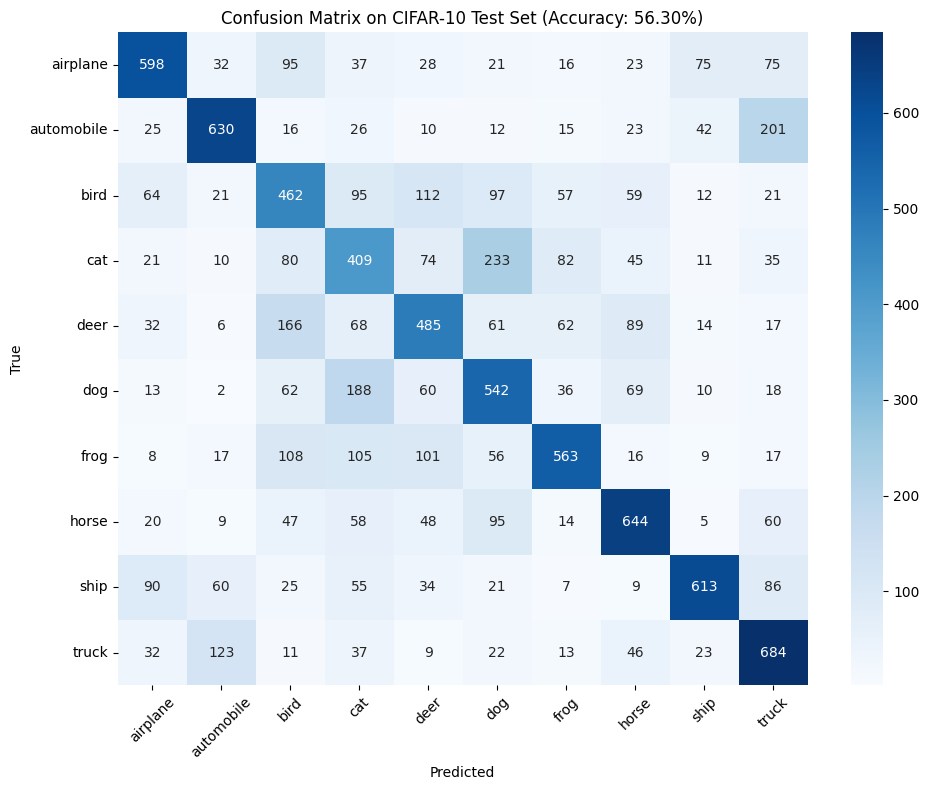

In [125]:
classes = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

all_preds = []
all_targets = []

model.load_state_dict(best_model_wts)
model.eval()

with torch.no_grad():
    for x_batch, y_batch in test_loader:
        x_batch = x_batch.to(device)
        y_batch = y_batch.to(device)

        outputs = model(x_batch)
        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(y_batch.cpu().numpy())

cm = confusion_matrix(all_targets, all_preds)
accuracy = np.mean(np.array(all_preds) == np.array(all_targets)) * 100

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
plt.title(f'Confusion Matrix on CIFAR-10 Test Set (Accuracy: {accuracy:.2f}%)')
plt.ylabel('True')
plt.xlabel('Predicted')
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

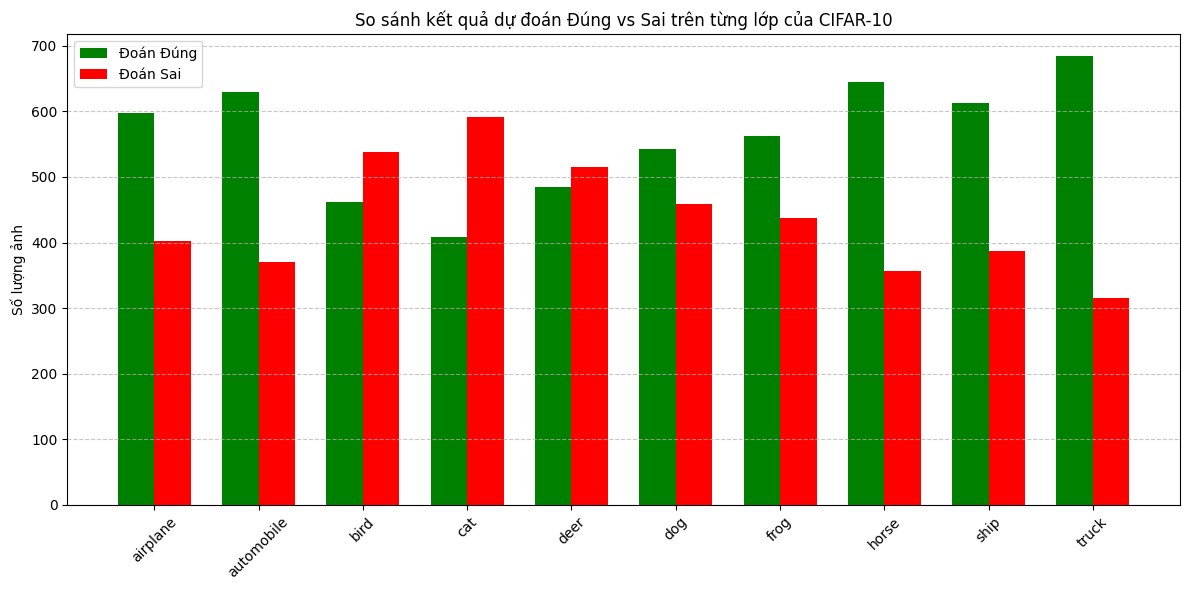

In [126]:
# Biểu đồ cột so sánh số lượng dự đoán đúng và sai cho từng lớp
correct_per_class = np.diag(cm)
total_per_class = np.sum(cm, axis=1)
incorrect_per_class = total_per_class - correct_per_class

x = np.arange(len(classes))
width = 0.35

fig, ax = plt.subplots(figsize=(12, 6))
rects1 = ax.bar(x - width/2, correct_per_class, width, label='Đoán Đúng', color='green')
rects2 = ax.bar(x + width/2, incorrect_per_class, width, label='Đoán Sai', color='red')

ax.set_ylabel('Số lượng ảnh')
ax.set_title('So sánh kết quả dự đoán Đúng vs Sai trên từng lớp của CIFAR-10')
ax.set_xticks(x)
ax.set_xticklabels(classes, rotation=45)
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.7)

fig.tight_layout()
plt.show()

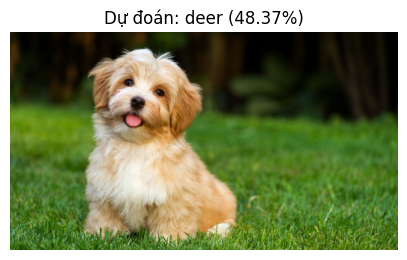

In [127]:
model.load_state_dict(best_model_wts)
model.eval()
with torch.no_grad():
    img_tensor = img_tensor1.to(device)
    output = model(img_tensor)
    probabilities = torch.nn.functional.softmax(output, dim=1)[0]
    _, pred = torch.max(output, 1)
    predicted_class = classes[pred.item()]
    confidence = probabilities[pred.item()].item() * 100

plt.figure(figsize=(5, 5))
plt.imshow(img1)
plt.title(f'Dự đoán: {predicted_class} ({confidence:.2f}%)')
plt.axis('off')
plt.show()

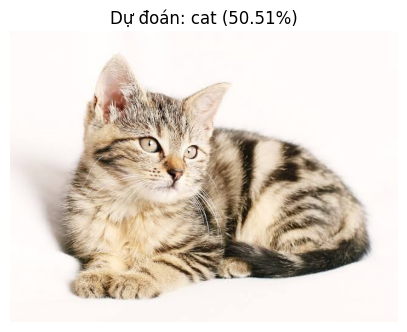

In [128]:
model.load_state_dict(best_model_wts)
model.eval()
with torch.no_grad():
    img_tensor2 = img_tensor2.to(device)
    output = model(img_tensor2)
    probabilities = torch.nn.functional.softmax(output, dim=1)[0]
    _, pred = torch.max(output, 1)
    predicted_class = classes[pred.item()]
    confidence = probabilities[pred.item()].item() * 100

plt.figure(figsize=(5, 5))
plt.imshow(img2)
plt.title(f'Dự đoán: {predicted_class} ({confidence:.2f}%)')
plt.axis('off')
plt.show()

## Kết luận cho hai mô hình1
 CNN (Convolutional Neural Network)

— Mô hình tối ưu cho dữ liệu ảnhĐộ chính xác vượt trội (> 80%): CNN vượt xa MLP nhờ khả năng trích xuất đặc trưng không gian 2D (cạnh, góc, kết cấu, hình dạng) thông qua các lớp Cuộn (Convolutional layers).Khả năng tổng quát hóa (Generalization) tốt: Dù trong quá trình huấn luyện, hai lớp Dog (Chó) và Cat (Mèo) thường xuyên bị nhầm lẫn với nhau (do đặc trưng ngoại hình, tư thế và kích thước tương đồng), mô hình vẫn học được các đường nét đặc trưng cốt lõi. Nhờ đó, khi đưa ảnh hoàn toàn mới ngoài thực tế vào, CNN vẫn phân biệt và dự đoán đúng.Tối ưu tính toán: Nhờ cơ chế Chia sẻ trọng số (Weight Sharing) của Kernel cuộn, CNN dùng ít tham số hơn để đại diện cho bức ảnh nhưng mang lại hiệu quả biểu diễn cao hơn hẳn.

2. Mạng Perceptron đa lớp MLP (Multi-Layer Perceptron)

— Hạn chế khi xử lý dữ liệu thị giác Độ chính xác thấp (56.30%): Việc phẳng hóa (flatten) ảnh $32 \times 32 \times 3$ thành vector 1D ($3072$ đặc trưng) làm mất hoàn toàn cấu trúc không gian và mối tương quan giữa các pixel lân cận. MLP coi mỗi pixel là một biến độc lập, dẫn đến khả năng trích xuất hình dạng vật thể rất kém.Dễ bị đoán mò / nhầm lẫn vô lý: Việc dự đoán ảnh con chó thành "hươu" (deer) phản ánh rõ việc mô hình bị phụ thuộc vào các yếu tố nhiễu nền (ví dụ: bãi cỏ xanh lá cây thường xuất hiện trong ảnh hươu) thay vì học được các đặc trưng thực sự của con vật.Chi phí tính toán lớn & Tốn thời gian: Vì mỗi neuron ở lớp sau phải kết nối với tất cả neuron ở lớp trước (Fully Connected), số lượng trọng số bùng nổ rất nhanh. Việc phải tăng thêm nhiều lớp tuyến tính để cố gắng học dữ liệu phức tạp khiến mô hình vừa nặng, vừa tốn thời gian tính toán mà hiệu quả mang lại không cao.

Đánh giá chung: Đối với dữ liệu thị giác (Hình ảnh), CNN là sự lựa chọn bắt buộc và vượt trội hoàn toàn so với MLP. MLP chỉ phù hợp cho dữ liệu dạng bảng (Tabular Data) hoặc các bài toán phân loại đơn giản với kích thước đầu vào nhỏ.